# Experiment 7: Text Classification using Deep Learning Models

**Aim:** To implement sentiment analysis on the IMDB Movie Reviews dataset (50,000 reviews) using Logistic Regression, LSTM, a Vanilla Transformer and a pretrained BERT model, and to compare all the models using F1-score, Precision, Recall and the Confusion Matrix.

**Dataset:** IMDB Dataset of 50K Movie Reviews (`IMDB Dataset.csv`) with two columns: `review` (text) and `sentiment` (positive / negative).

**Parts:**
1. Logistic Regression (TF-IDF features)
2. LSTM
3. Vanilla Transformer (built from scratch)
4. BERT (pretrained, fine-tuned)
5. Comparative analysis

In [1]:
import os

for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/arnavpatel07/imdb-dataset/IMDB20Dataset.csv


In [2]:
# Cell 2: load data, clean it, split it
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("/kaggle/input/datasets/arnavpatel07/imdb-dataset/IMDB20Dataset.csv")
df = df.drop_duplicates().reset_index(drop=True)   # remove 418 repeated reviews

# remove html tags, lowercase, encode labels (positive = 1, negative = 0)
df["review"] = df["review"].str.replace(r"<.*?>", " ", regex=True).str.lower()
df["label"] = (df["sentiment"] == "positive").astype(int)

# 80/20 split; stratify keeps the positive/negative ratio equal in both sets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])
print(train_df.shape, test_df.shape)
print(df["label"].value_counts())

(39665, 3) (9917, 3)
label
1    24884
0    24698
Name: count, dtype: int64


In [3]:
# Cell 3: one evaluation function reused for every model, so the comparison is fair
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

results = {}

def evaluate(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()   # TN, FP, FN, TP counts
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }
    print(classification_report(y_true, y_pred, target_names=["negative", "positive"]))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["negative", "positive"], cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

## Part 1: Logistic Regression

Reviews are converted to numbers using TF-IDF (Term Frequency–Inverse Document Frequency) with unigrams and bigrams (single words and two-word pairs), and a Logistic Regression classifier is trained on them.

**Why this model:** it is the classical baseline. It is fast and simple, so it shows how much the deep models improve on a basic method.
**Why bigrams:** they capture phrases like "not good", which single words miss.

              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.92      0.91      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



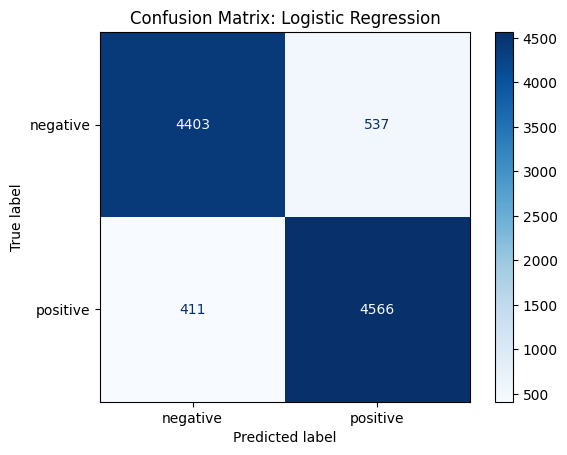

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# TF-IDF features; vocabulary is learned from training data only
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train_df["review"])
X_test_tfidf = tfidf.transform(test_df["review"])

# train the classifier and predict on the test set
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, train_df["label"])
lr_pred = lr_model.predict(X_test_tfidf)

evaluate("Logistic Regression", test_df["label"], lr_pred)

## Part 2: LSTM (Long Short-Term Memory)

Reviews are tokenized and converted to integer sequences (vocabulary of 20,000 words, length 256), then passed through an embedding layer and an LSTM. The final hidden state is used to classify the review as positive or negative.

**Why LSTM:** it reads words in order and remembers earlier context, which Logistic Regression cannot do.
**Why 256 words and 20,000 vocabulary:** a balance between keeping enough of each review and keeping training fast.
The data pipeline and training functions defined here are reused in Part 3.

In [5]:
import re
import numpy as np
import torch
import torch.nn as nn
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

MAX_LEN, VOCAB_SIZE = 256, 20000
tokenize = lambda text: re.findall(r"[a-z']+", text)   # split text into words

# vocabulary from training data only (0 = padding, 1 = unknown word)
counter = Counter(w for t in train_df["review"] for w in tokenize(t))
word2idx = {w: i + 2 for i, (w, _) in enumerate(counter.most_common(VOCAB_SIZE - 2))}

def encode(text):
    ids = [word2idx.get(w, 1) for w in tokenize(text)][:MAX_LEN]   # words -> numbers, cut at 256
    return [0] * (MAX_LEN - len(ids)) + ids                        # pad short reviews at the front

def make_loader(data, shuffle):
    X = torch.tensor([encode(t) for t in data["review"]])
    y = torch.tensor(data["label"].values)
    return DataLoader(TensorDataset(X, y), batch_size=64, shuffle=shuffle)

train_loader = make_loader(train_df, True)
test_loader = make_loader(test_df, False)

Device: cuda


In [6]:
# shared training and prediction functions (also used by the Transformer)
def train_model(model, epochs, lr):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        total = 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(X), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # prevents exploding gradients
            optimizer.step()
            total += loss.item()
        print(f"Epoch {epoch + 1}/{epochs}, loss = {total / len(train_loader):.4f}")

def predict(model):
    model.eval()
    preds = []
    with torch.no_grad():
        for X, _ in test_loader:
            preds.extend(model(X.to(device)).argmax(1).cpu().numpy())
    return np.array(preds)

Epoch 1/5, loss = 0.5875
Epoch 2/5, loss = 0.4353
Epoch 3/5, loss = 0.3234
Epoch 4/5, loss = 0.2539
Epoch 5/5, loss = 0.1991
              precision    recall  f1-score   support

    negative       0.92      0.82      0.87      4940
    positive       0.84      0.93      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



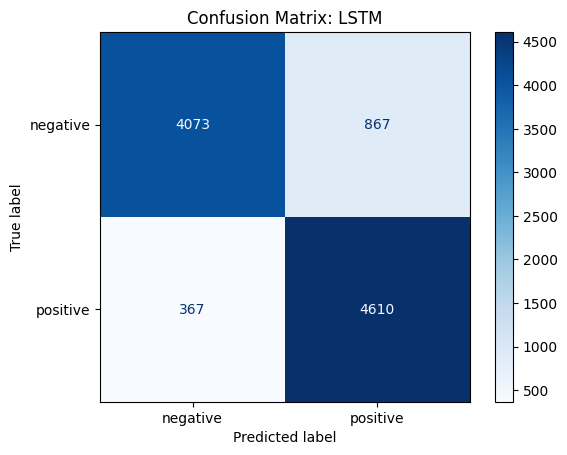

In [7]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, emb_dim=128, hidden=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)   # word -> vector
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.3)                                      # reduces overfitting
        self.fc = nn.Linear(hidden, 2)                                      # 2 classes

    def forward(self, x):
        _, (h, _) = self.lstm(self.embedding(x))   # h = final hidden state (summary of the review)
        return self.fc(self.dropout(h[-1]))

lstm_model = LSTMClassifier()
train_model(lstm_model, epochs=5, lr=1e-3)

lstm_pred = predict(lstm_model)
evaluate("LSTM", test_df["label"].values, lstm_pred)

## Part 3: Vanilla Transformer

A Transformer encoder is built from scratch (no pretraining): word embeddings plus learned positional embeddings, followed by 2 multi-head self-attention encoder layers. The outputs are average-pooled (ignoring padding) and passed to a linear layer for classification.

**Why positional embeddings:** self-attention has no sense of word order by itself, so position information is added.
**Why a small model (2 layers, 4 heads):** with only about 40,000 training reviews, a bigger model would overfit and train slowly.

Epoch 1/5, loss = 0.4992
Epoch 2/5, loss = 0.3377
Epoch 3/5, loss = 0.2653
Epoch 4/5, loss = 0.2104
Epoch 5/5, loss = 0.1635
              precision    recall  f1-score   support

    negative       0.83      0.90      0.86      4940
    positive       0.89      0.82      0.85      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



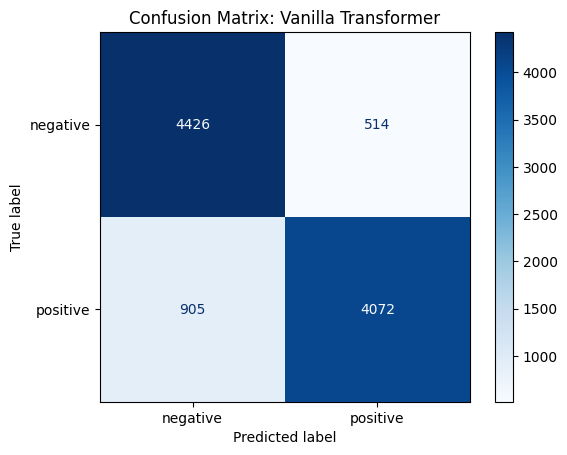

In [8]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, d_model=128, heads=4, layers=2, ff=256, max_len=MAX_LEN):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_embedding = nn.Embedding(max_len, d_model)    # learns a vector for each position
        layer = nn.TransformerEncoderLayer(d_model, heads, ff, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.fc = nn.Linear(d_model, 2)

    def forward(self, x):
        pad_mask = x == 0                                       # True where the token is padding
        positions = torch.arange(x.size(1), device=x.device)
        h = self.embedding(x) + self.pos_embedding(positions)   # word meaning + word position
        h = self.encoder(h, src_key_padding_mask=pad_mask)      # self-attention ignores padding
        # mean pooling over real (non-pad) tokens
        h = h.masked_fill(pad_mask.unsqueeze(-1), 0).sum(1) / (~pad_mask).sum(1, keepdim=True).clamp(min=1)
        return self.fc(h)

transformer_model = TransformerClassifier()
train_model(transformer_model, epochs=5, lr=5e-4)

transformer_pred = predict(transformer_model)
evaluate("Vanilla Transformer", test_df["label"].values, transformer_pred)

## Part 4: BERT (Bidirectional Encoder Representations from Transformers), Pretrained

The pretrained `bert-base-uncased` model from Hugging Face is fine-tuned for sentiment classification.

**Why bert-base-uncased:** the reviews are already lowercase, and the "base" size trains in reasonable time on a free GPU (Graphics Processing Unit); the "large" version would be much slower.
**Why 2 epochs and a learning rate of 2e-5:** BERT already knows language from pretraining, so it only needs gentle adjustment. Longer or faster training risks overfitting.
**Why 256 tokens:** keeps training time reasonable; some long reviews are cut.
AMP (Automatic Mixed Precision) is used to speed up GPU training.

In [9]:
!pip install -q transformers

In [10]:
from transformers import BertTokenizerFast, BertForSequenceClassification, get_linear_schedule_with_warmup

tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

def bert_loader(data, shuffle):
    # BERT has its own tokenizer; it returns token ids and an attention mask (1 = real token, 0 = padding)
    enc = tokenizer(list(data["review"]), truncation=True, padding="max_length",
                    max_length=256, return_tensors="pt")
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(data["label"].values))
    return DataLoader(ds, batch_size=32, shuffle=shuffle)

bert_train_loader = bert_loader(train_df, True)
bert_test_loader = bert_loader(test_df, False)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [11]:
# load pretrained BERT with a new 2-class output layer
bert_model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2).to(device)

epochs = 2
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)
total_steps = epochs * len(bert_train_loader)
# learning rate warms up for the first 10% of steps, then decreases linearly
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(enabled=use_amp)

for epoch in range(epochs):
    bert_model.train()
    total = 0
    for ids, mask, y in bert_train_loader:
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            loss = bert_model(input_ids=ids, attention_mask=mask, labels=y).loss
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += loss.item()
    print(f"Epoch {epoch + 1}/{epochs}, loss = {total / len(bert_train_loader):.4f}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2, loss = 0.2715
Epoch 2/2, loss = 0.1329


              precision    recall  f1-score   support

    negative       0.93      0.92      0.93      4940
    positive       0.92      0.94      0.93      4977

    accuracy                           0.93      9917
   macro avg       0.93      0.93      0.93      9917
weighted avg       0.93      0.93      0.93      9917



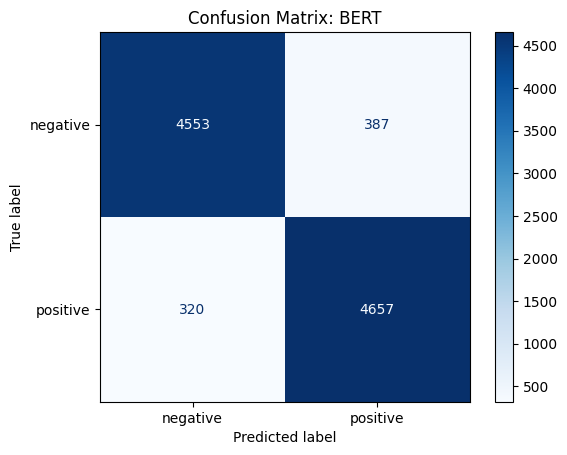

In [12]:
# predict on the test set and evaluate
bert_model.eval()
bert_pred = []
with torch.no_grad():
    for ids, mask, _ in bert_test_loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = bert_model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        bert_pred.extend(logits.argmax(1).cpu().numpy())

evaluate("BERT", test_df["label"].values, np.array(bert_pred))

## Part 5: Comparative Analysis

All four models are compared on the same test set using Accuracy, Precision, Recall and F1-score. Errors are compared using confusion matrix counts: FP (False Positive) = negative review predicted positive, FN (False Negative) = positive review predicted negative.

**Observations**
- **Logistic Regression:** a strong baseline because TF-IDF with bigrams captures sentiment words well; it trains in seconds but cannot understand word order or context.
- **LSTM:** reads the review in order, but long reviews and limited training data hold it back, and it may not beat the TF-IDF baseline.
- **Vanilla Transformer:** uses self-attention, but without pretraining it must learn language from the training reviews alone, so it performs close to the LSTM.
- **BERT:** best performance, because pretraining on a huge corpus gives deep contextual understanding; the cost is longer training time and needing a GPU.
- **Confusion matrix:** more FN means a model misses positive reviews; more FP means it wrongly labels negative reviews as positive.

**Conclusion:** BERT gives the best F1-score, showing that pretrained contextual models outperform models trained from scratch on this dataset.

,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
Logistic Regression,0.9044,0.8948,0.9174,0.9060,4403,537,411,4566
LSTM,0.8756,0.8417,0.9263,0.8820,4073,867,367,4610
Vanilla Transformer,0.8569,0.8879,0.8182,0.8516,4426,514,905,4072
BERT,0.9287,0.9233,0.9357,0.9294,4553,387,320,4657


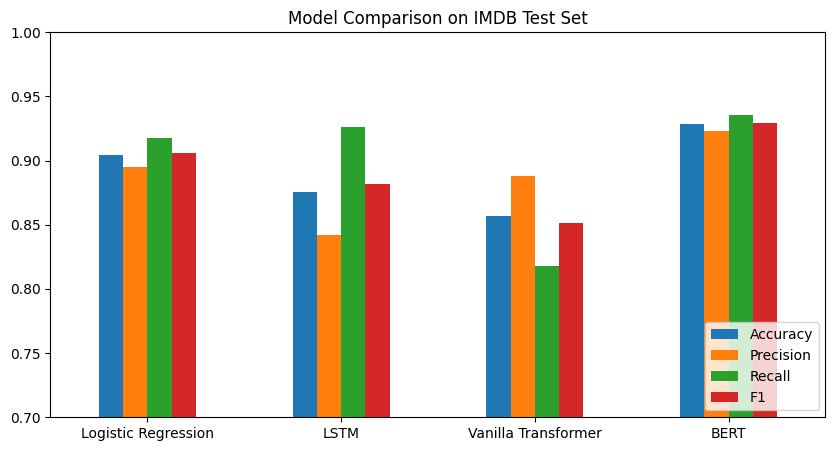

In [13]:
# comparison table and bar chart
comparison = pd.DataFrame(results).T
comparison[["TN", "FP", "FN", "TP"]] = comparison[["TN", "FP", "FN", "TP"]].astype(int)
display(comparison.round(4))

comparison[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5), ylim=(0.7, 1.0))
plt.title("Model Comparison on IMDB Test Set")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()